In [1]:
import sys

print(sys.executable)

e:\Final_Year_Project\Emoji-Sentiment-Analysis\venv\Scripts\python.exe


In [2]:
import pandas as pd

df = pd.read_csv(
    "../dataset/social_media_comments.csv",
    encoding="utf-8"
)

print(df.head())
print(df.shape)
print(df.columns)
print(df.iloc[0]["comment"])

                              comment sentiment
0  I absolutely love this product 😍❤️  positive
1                 This is amazing! 😊🔥  positive
2             Best experience ever ❤️  positive
3       I really enjoyed this movie 😍  positive
4                      Great work! 👍😊  positive
(20, 2)
Index(['comment', 'sentiment'], dtype='str')
I absolutely love this product 😍❤️


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully")

Libraries imported successfully


In [4]:
df = pd.read_csv(
    "../dataset/social_media_comments.csv",
    encoding="utf-8"
)

print("Dataset loaded successfully")

Dataset loaded successfully


In [5]:
df

,comment,sentiment
0,I absolutely love this product 😍❤️,positive
1,This is amazing! 😊🔥,positive
2,Best experience ever ❤️,positive
3,I really enjoyed this movie 😍,positive
4,Great work! 👍😊,positive
5,This is terrible 😡,negative
6,I hate this product 😠💔,negative
7,Worst experience ever 😭,negative
8,Very disappointing 😞,negative
9,This service is horrible 😡👎,negative


In [6]:
df = pd.read_csv(
    "../dataset/social_media_comments.csv",
    encoding="utf-8"
)

print("Dataset loaded successfully")

Dataset loaded successfully


In [7]:
df.head(10)

,comment,sentiment
0,I absolutely love this product 😍❤️,positive
1,This is amazing! 😊🔥,positive
2,Best experience ever ❤️,positive
3,I really enjoyed this movie 😍,positive
4,Great work! 👍😊,positive
5,This is terrible 😡,negative
6,I hate this product 😠💔,negative
7,Worst experience ever 😭,negative
8,Very disappointing 😞,negative
9,This service is horrible 😡👎,negative


In [8]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 20
Number of columns: 2


In [9]:
print(df.columns.tolist())

['comment', 'sentiment']


In [10]:
print(df.isnull().sum())

comment      0
sentiment    0
dtype: int64


In [11]:
print(df["sentiment"].value_counts())

sentiment
positive    7
negative    7
neutral     6
Name: count, dtype: int64


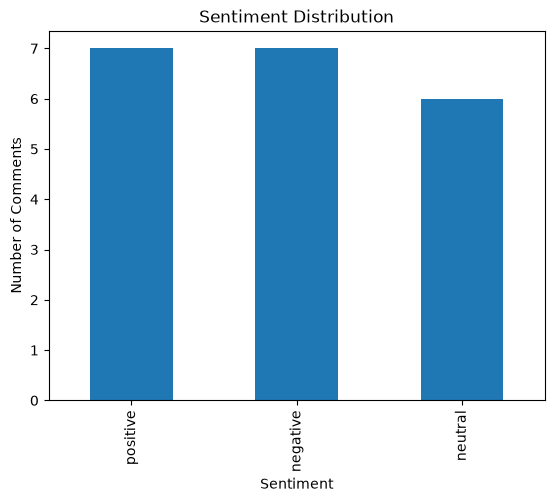

In [12]:
df["sentiment"].value_counts().plot(
    kind="bar",
    title="Sentiment Distribution"
)

plt.xlabel("Sentiment")
plt.ylabel("Number of Comments")
plt.show()

In [13]:
import emoji

def contains_emoji(text):
    return any(char in emoji.EMOJI_DATA for char in str(text))

df["has_emoji"] = df["comment"].apply(contains_emoji)

print(df["has_emoji"].value_counts())

has_emoji
True     17
False     3
Name: count, dtype: int64


In [14]:
print(df[df["has_emoji"]][["comment", "sentiment"]])

                               comment sentiment
0   I absolutely love this product 😍❤️  positive
1                  This is amazing! 😊🔥  positive
2              Best experience ever ❤️  positive
3        I really enjoyed this movie 😍  positive
4                       Great work! 👍😊  positive
5                   This is terrible 😡  negative
6               I hate this product 😠💔  negative
7              Worst experience ever 😭  negative
8                 Very disappointing 😞  negative
9          This service is horrible 😡👎  negative
11                        It is okay 🙂   neutral
12             The movie was average 😐   neutral
14          Nothing special about it 😶   neutral
15          Absolutely fantastic! 😍❤️🔥  positive
16              Very bad experience 😡😭  negative
18          I am so happy with this! 🥰  positive
19          I don't like this at all 😒  negative


In [15]:
def extract_emojis(text):
    return [
        char for char in str(text)
        if char in emoji.EMOJI_DATA
    ]

df["emojis"] = df["comment"].apply(extract_emojis)

df[["comment", "emojis", "sentiment"]].head(10)

,comment,emojis,sentiment
0,I absolutely love this product 😍❤️,"[😍, ❤]",positive
1,This is amazing! 😊🔥,"[😊, 🔥]",positive
2,Best experience ever ❤️,[❤],positive
3,I really enjoyed this movie 😍,[😍],positive
4,Great work! 👍😊,"[👍, 😊]",positive
5,This is terrible 😡,[😡],negative
6,I hate this product 😠💔,"[😠, 💔]",negative
7,Worst experience ever 😭,[😭],negative
8,Very disappointing 😞,[😞],negative
9,This service is horrible 😡👎,"[😡, 👎]",negative


In [16]:
df["emoji_count"] = df["emojis"].apply(len)

print(df[["comment", "emoji_count", "sentiment"]])

                               comment  emoji_count sentiment
0   I absolutely love this product 😍❤️            2  positive
1                  This is amazing! 😊🔥            2  positive
2              Best experience ever ❤️            1  positive
3        I really enjoyed this movie 😍            1  positive
4                       Great work! 👍😊            2  positive
5                   This is terrible 😡            1  negative
6               I hate this product 😠💔            2  negative
7              Worst experience ever 😭            1  negative
8                 Very disappointing 😞            1  negative
9          This service is horrible 😡👎            2  negative
10          The product arrived today.            0   neutral
11                        It is okay 🙂            1   neutral
12             The movie was average 😐            1   neutral
13   I received the package yesterday.            0   neutral
14          Nothing special about it 😶            1   neutral
15      

In [17]:
print("Total emojis:", df["emoji_count"].sum())
print("Average emojis per comment:", df["emoji_count"].mean())

Total emojis: 25
Average emojis per comment: 1.25
